# How far have Adelaide rents risen, suburb by suburb?

The SA Housing Trust's quarterly Private Rent Report gives, for every suburb, the number of rental bonds lodged that
quarter and their median weekly rent, for flats and units, houses and all dwellings. These are rents for **new
leases** (a bond is lodged when a lease starts), not what every tenant pays.

The tables in `../data` were read from 53 reports (March 2013 to June 2026), the suburb names matched to the ABS
Suburbs and Localities with [Plotlay](https://www.getplotlay.com), and cut to Greater Adelaide (ABS GCCSA 4GADE). This
notebook reads only `../data`.

In [1]:
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
q = pd.read_csv(f'{DATA}/tables/quarters.csv', dtype={'code': str})
s = pd.read_csv(f'{DATA}/tables/suburbs.csv', dtype={'code': str})
m = pd.read_csv(f'{DATA}/tables/metro.csv')
print(q.code.nunique(), 'suburbs,', q.quarter.nunique(), 'quarters,', len(q), 'suburb quarters')

484 suburbs, 53 quarters, 21638 suburb quarters


## 1. Greater Adelaide, quarter by quarter

Each quarter's Greater Adelaide figure is the suburbs' medians averaged, weighted by their bonds (the reports give no
bond-by-bond data, so a true median of all bonds cannot be worked out). The report's own metropolitan median runs within
about 2% of it (`checks/region_check.csv` in the build).

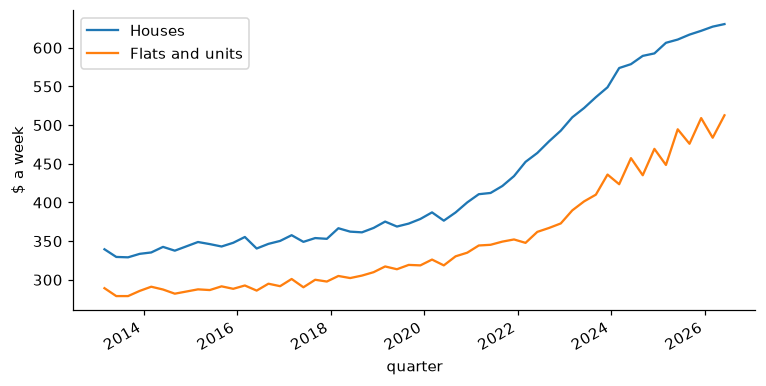

,,2015,year to June 2026,rise %
0,All dwellings,319,569,78.2
1,Houses,347,625,80.0
2,Flats and units,288,496,72.3


In [2]:
ax = m.set_index(pd.to_datetime(m.quarter + '-01'))[['rent_houses', 'rent_units']].plot(figsize=(8, 4), ylabel='$ a week')
ax.legend(['Houses', 'Flats and units']); plt.show()
BASE = ['2015-03', '2015-06', '2015-09', '2015-12']; LATEST = ['2025-09', '2025-12', '2026-03', '2026-06']
rows = []
for col, name in (('rent_all', 'All dwellings'), ('rent_houses', 'Houses'), ('rent_units', 'Flats and units')):
    a, b = m[m.quarter.isin(BASE)][col].median(), m[m.quarter.isin(LATEST)][col].median()
    rows.append({'': name, '2015': round(a), 'year to June 2026': round(b), 'rise %': round(100 * (b / a - 1), 1)})
pd.DataFrame(rows)

## 2. Small counts

A quarter's median is shown only where 10 or more new bonds were lodged; a suburb's change since 2015 only where both
12-month windows have 40 or more. The reports print counts of 1 to 5 as `*`; those count as 3 for the weights.

In [3]:
print(q.shown.value_counts().to_string())
print(s.state.value_counts().to_string())

shown
shown                      16169
fewer than 10 new bonds     5448
one-off batch, left out       21
state
compared     261
few bonds    207
no bonds      25


## 3. One-off batches

A few suburb quarters carry several hundred bonds at about half the suburb's usual rent: a block of tenancies lodging
at once, not the market moving. They are left out (`batch = 1`). The rule: at least 3 times the suburb's usual quarterly
bonds, 30 or more, and a median under three quarters of its usual median.

In [4]:
q[q.batch == 1][['name', 'quarter', 'bonds', 'median_all']].sort_values('bonds', ascending=False)

,name,quarter,bonds,median_all
12107,Mitchell Park (SA),2015-12,315.0,153.000
12108,Mitchell Park (SA),2016-03,305.0,172.700
4644,Elizabeth Grove,2015-12,250.0,107.900
15168,Pennington,2018-03,240.0,101.500
12449,Morphettville,2017-12,175.0,168.000
4856,Elizabeth Vale,2015-12,175.0,108.700
11160,Mansfield Park,2018-03,140.0,165.000
21312,Woodville Gardens,2018-06,115.0,168.685
14833,Park Holme,2017-12,100.0,202.700
4645,Elizabeth Grove,2016-03,85.0,147.400


## 4. The change since 2015, suburb by suburb

Each window's typical rent is the middle of its four quarterly medians, so one odd quarter cannot move it.

In [5]:
c = s[s.ok_all == 1]
print(len(c), 'suburbs compared; median rise', c.change_pct_all.median(), '%;', (c.change_pct_all >= 100).sum(), 'doubled or more')
for lab in ('houses', 'units'):
    t = s[s[f'ok_{lab}'] == 1].sort_values(f'change_pct_{lab}', ascending=False)
    print(f'\n{lab}: {len(t)} suburbs'); print(t[['name', f'rent_2015_{lab}', f'rent_2026_{lab}', f'change_pct_{lab}']].head(10).to_string(index=False))

261 suburbs compared; median rise 83.3 %; 35 doubled or more

houses: 192 suburbs
             name  rent_2015_houses  rent_2026_houses  change_pct_houses
        Elizabeth             232.0             535.0              130.1
  Elizabeth South             215.0             475.0              120.9
  Elizabeth North             225.0             492.0              118.9
   Elizabeth East             232.0             509.0              118.8
  Elizabeth Downs             235.0             500.0              112.8
    Port Willunga             285.0             596.0              109.2
            Moana             330.0             689.0              108.7
     Davoren Park             239.0             498.0              108.2
Smithfield Plains             250.0             520.0              108.0
   Elizabeth Vale             240.0             499.0              107.8

units: 78 suburbs
             name  rent_2015_units  rent_2026_units  change_pct_units
           Bowden         

## 5. On the map

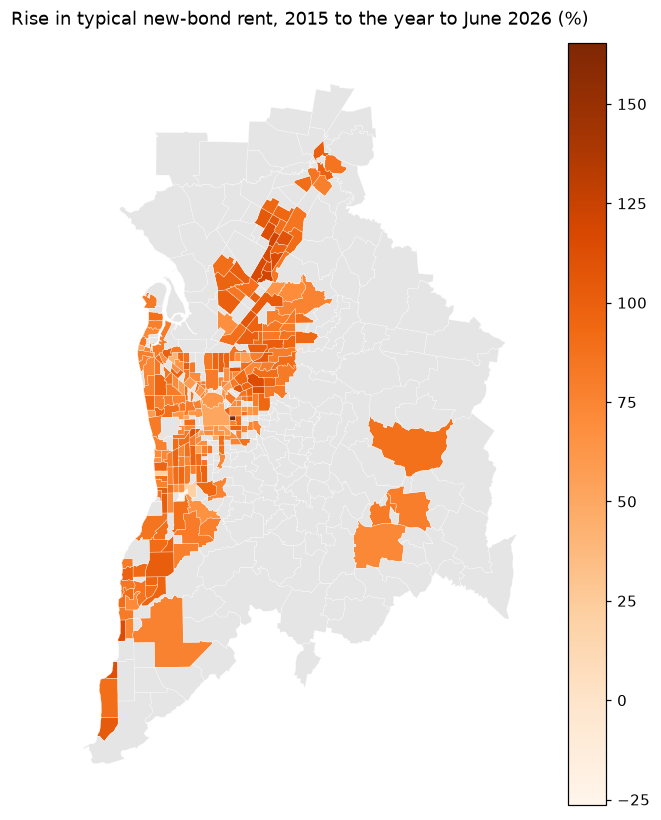

In [6]:
g = gpd.read_file(f'{DATA}/geometry/suburbs.geojson').merge(s[['code', 'change_pct_all']], left_on='key', right_on='code', how='left')
ax = g.to_crs(9473).plot(column='change_pct_all', cmap='Oranges', legend=True, missing_kwds={'color': '#e5e5e5'}, figsize=(7, 9), linewidth=0.2, edgecolor='white')
ax.set_axis_off(); ax.set_title('Rise in typical new-bond rent, 2015 to the year to June 2026 (%)'); plt.show()

## Read it carefully

- **New bonds only.** A sitting tenant's rent is not in these figures; new leases move first, so they run ahead of all
  rents.
- **The mix moves the median.** The City of Adelaide and the suburbs round Flinders University carry many rooms let to
  students; a suburb's median moves with what was let that quarter, not only with prices.
- **Names, not codes.** The report names suburbs; 1,310 of 1,375 spellings matched an ABS suburb (99.95% of bonds).
  Riverlea Park, a new suburb from 2024, has no 2021 ABS area.